In [1]:
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent.parent
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'
FIGURE_OUT = PROJECT_ROOT / 'figures'

import sys
sys.path.append(str(PROJECT_ROOT))

import matplotlib.pyplot as plt
from src.utils.util import load_sensor_dict
import numpy as np

savefigs = True
fig_version = 'V03'

In [3]:
# misr_obs = load_sensor_dict('/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc')
misr_obs_file = INTERIM_DATA / 'AT3D_OBS_CAMP2Ex_RF17_default.nc'
misr_obs = load_sensor_dict(misr_obs_file)

## Figure 4: MISR observation and cloud mask

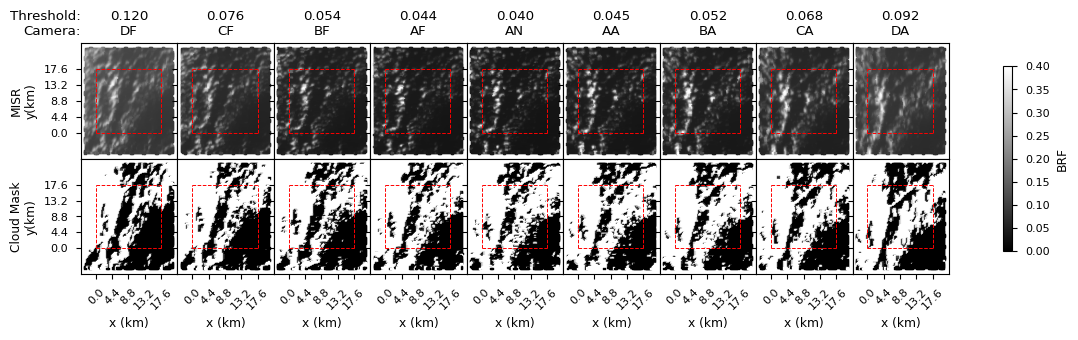

In [4]:
vmin = 0
vmax = 0.4
vrange = 0.18
s = 3
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
ths = [0.120, 0.076, 0.054, 0.044, 0.040, 0.045, 0.052, 0.068, 0.092]

plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(2, 9, figsize=(14, 3), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.0, hspace=0.0)

for i, mo in enumerate(misr_obs['MISR']['sensor_list']):
    c1 = ax[0, i].scatter(
        mo.cam_x.data,
        mo.cam_y.data,
        c = (np.pi * mo.I.data) / mo.mu0,
        s = s,
        cmap = 'gray',
        vmin = vmin,
        vmax = vmax,
        marker = 's'
    )
    c2 = ax[1, i].scatter(
        mo.cam_x.data,
        mo.cam_y.data,
        c = ((np.pi * mo.I.data) / mo.mu0) > ths[i],
        s = s,
        cmap = 'gray',
        vmin = 0,
        vmax = 1,
        marker = 's'
    )
    title = '{:.3f}\n{}'.format(ths[i], mo.name)
    ax[0, i].set_title(title)
    ax[1, i].set_xlabel('x (km)')
plt.colorbar(c1, ax=ax[:, :], label='BRF', shrink=0.8)
ax[0, 0].set_ylabel('MISR\ny(km)')
ax[1, 0].set_ylabel('Cloud Mask\ny(km)')

ls = '--'
lw = 0.7
for a in ax.flat:
    a.plot([0, 0], [0, 17.6], c='r', ls=ls, lw=lw)
    a.plot([0, 17.6], [0, 0], c='r', ls=ls, lw=lw)
    a.plot([17.6, 17.6], [0, 17.6], c='r', ls=ls, lw=lw)
    a.plot([0, 17.6], [17.6, 17.6], c='r', ls=ls, lw=lw)
    a.set_xticks(ticks)
    a.set_xticklabels(ticks, rotation=45)
    a.set_yticks(ticks)

ax[0,0].set_title('Threshold:\nCamera:', loc='right', x=0)

if(savefigs):
    plt.savefig(
        FIGURE_OUT / '{}_figure04_MISR_obs.png'.format(fig_version),
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )